In [1]:
# !pip install -r requirements.txt

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import cv2
import json
import numpy as np
from PIL import Image
import os
import glob

# Prepare data

In [3]:
image_paths = glob.glob('./data/*.jpg')
json_paths = [pth.replace('jpg', 'json') for pth in image_paths]
image_paths, json_paths

(['./data\\001_IT135673_1.jpg',
  './data\\003_IT158279_1.jpg',
  './data\\004_IT158286_1.jpg',
  './data\\006_IT158412_1.jpg',
  './data\\008_IT158764_1.jpg',
  './data\\009_IT221893_1.jpg',
  './data\\010_IT223741_1.jpg',
  './data\\011_IT223788_1.jpg',
  './data\\012_IT225004_1.jpg'],
 ['./data\\001_IT135673_1.json',
  './data\\003_IT158279_1.json',
  './data\\004_IT158286_1.json',
  './data\\006_IT158412_1.json',
  './data\\008_IT158764_1.json',
  './data\\009_IT221893_1.json',
  './data\\010_IT223741_1.json',
  './data\\011_IT223788_1.json',
  './data\\012_IT225004_1.json'])

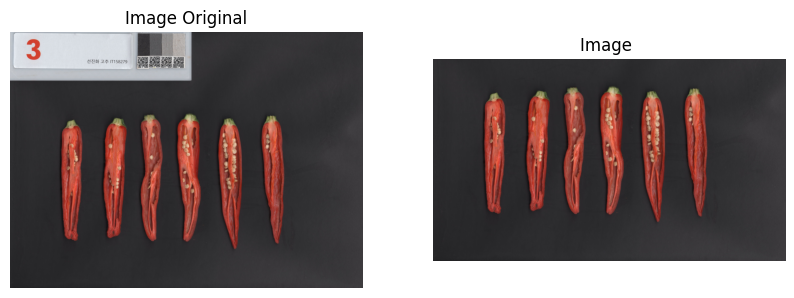

In [4]:
image = cv2.imread(image_paths[1])
image_RGB = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_crop = image_RGB[540:, :, :]

plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.imshow(image_RGB)
plt.title("Image Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_crop)
plt.title("Image ")
plt.axis("off")

plt.show()

# Get Bbox

### Detect bbox by threshold

In [5]:
# from segment import SegmentModel
from src.detect import DetectModel

model_detect = DetectModel(model_name='none')
# model_detect.predict(image_paths[0])

Use threshold for detect each chili fruit


In [6]:
path = image_paths[2]
masks = model_detect.predict(path)
image = cv2.imread(path)
H, W, _ = image.shape

for i, mask in enumerate(masks):
    x, y, w, h = mask
    # print(x,y,w,h)
    img = image[max(0, y-50):min(H,y+h+50), max(0,x-50):min(W,x+w+50)]
    cv2.imwrite(f"runs/detect/predict/output_{i}.jpg", img)
    # cv2.rectangle(image, (x-50, y-50), (x + w +50, y + h+50), (0, 255, 0), 2)

### Detect chili by model YOLO

- chưa load được model gọn nhẹ

# Segment for each chili

In [7]:
from src.segment import SegmentModel

model_seg = SegmentModel(weight_path='./pretrain/yolov8_segment_v1.pt', model_name='yolo')

In [8]:
import glob

img_paths = glob.glob('./runs/detect/predict/*.jpg')
imgs = [cv2.imread(path) for path in img_paths]
RGB_imgs = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB) for img in imgs]

results = model_seg.predict(RGB_imgs[0])

r = results['raw_results'][0]  # first image result


0: 640x224 12 seeds, 1 placenta, 1 endocarp, 282.2ms
Speed: 3.2ms preprocess, 282.2ms inference, 57.4ms postprocess per image at shape (1, 3, 640, 224)


In [9]:
[i['class_name'] for i in results['polygons']]

['placenta',
 'endocrap',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed']

In [10]:
names = r.names
masks = r.masks.data
polygons = r.masks.xy
xyxy = r.boxes.xyxy      # (N,4)
cls  = r.boxes.cls
conf = r.boxes.conf

In [11]:
masks.shape

torch.Size([14, 1726, 551])

# Test pipeline


0: 640x256 19 seeds, 2 placentas, 1 endocarp, 398.6ms
Speed: 1.7ms preprocess, 398.6ms inference, 46.2ms postprocess per image at shape (1, 3, 640, 256)
0 [358, 1145, 263, 817]

0: 640x256 21 seeds, 1 placenta, 1 endocarp, 298.5ms
Speed: 2.1ms preprocess, 298.5ms inference, 42.5ms postprocess per image at shape (1, 3, 640, 256)
1 [937, 1164, 244, 822]

0: 640x256 8 seeds, 1 placenta, 1 endocarp, 336.5ms
Speed: 1.1ms preprocess, 336.5ms inference, 11.7ms postprocess per image at shape (1, 3, 640, 256)
2 [1459, 1239, 209, 692]

0: 640x256 12 seeds, 1 placenta, 1 endocarp, 260.8ms
Speed: 1.3ms preprocess, 260.8ms inference, 15.3ms postprocess per image at shape (1, 3, 640, 256)
3 [1963, 1217, 209, 707]

0: 640x224 6 seeds, 1 placenta, 1 endocarp, 237.8ms
Speed: 1.2ms preprocess, 237.8ms inference, 12.0ms postprocess per image at shape (1, 3, 640, 224)
4 [2535, 1161, 236, 905]

0: 640x224 9 seeds, 1 placenta, 1 endocarp, 328.7ms
Speed: 1.4ms preprocess, 328.7ms inference, 29.2ms postproce

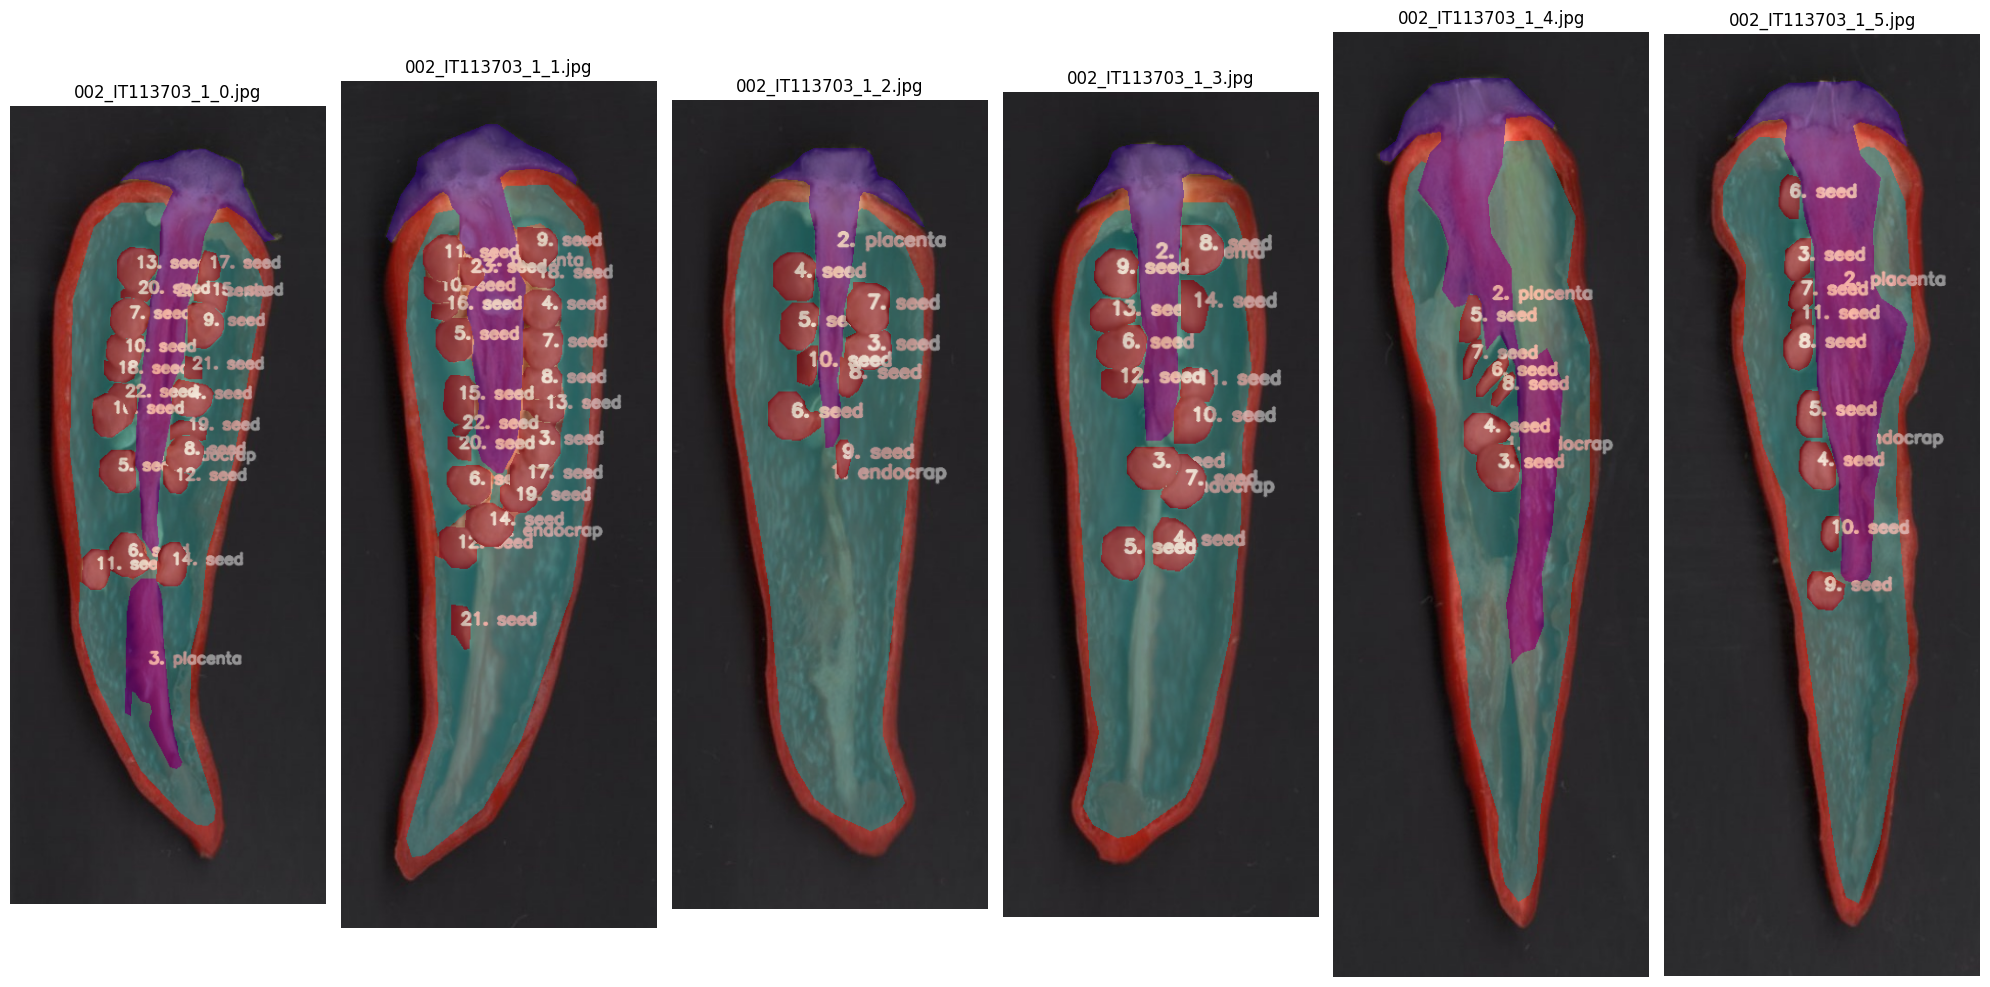

In [12]:
from src.object import Fruits

fruits = Fruits(r'D:\Workspace\dataset\jeju_segmentation\002_IT113703_1.jpg', model_detect, model_seg)
fruits.show()
# fruits.items[0].rseg

In [13]:
fruits.items[0].rseg['raw_results'][0].masks.xy[0]
fruits.items[0].polygons[0].keys()

dict_keys(['class_id', 'class_name', 'points', 'points_normalized'])

[308, 671, 1095, 2012]
[887, 1231, 1114, 2036]
[1409, 1718, 1189, 1981]
[1913, 2222, 1167, 1974]
[2485, 2821, 1111, 2116]
[3007, 3338, 1152, 2139]


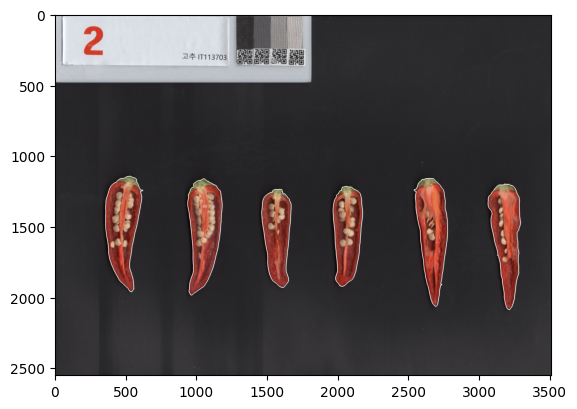

In [14]:
image = fruits.image.copy()
image = np.array(image)
for chili in fruits.items:
    contour, img =chili.get_contour()
    pos = chili.position
    print(pos)
    for i in range(len(contour[0])):
        contour[0][i][0][0] = contour[0][i][0][0] + pos[0]
        contour[0][i][0][1] = contour[0][i][0][1] + pos[2]
        # print(contour[0][i][0])
        # break
    cv2.drawContours(image, contour, -1, (255, 255, 255), 3)
    # chili.position
    # break
plt.imshow(image)
plt.show()

In [15]:
# !python predict.py --input_path ./data/ --name_model_seg yolo --weight_seg ./pretrain/yolov8_segment_v1.pt --save_csv

# Accuracy

# App demo